In [8]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier 
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
import seaborn as sns
import random
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
import time
from copy import deepcopy

### Part 1

### Code

In [9]:
# set random seed 42 is general approach usage
np.random.seed(42)
random.seed(41)

In [10]:
# get breast-cancer data vis sklearn
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# split
XTrain, XTest, yTrain, yTest = train_test_split(X, y, test_size=0.2, random_state=42)

# get feautres
scaler = StandardScaler()
XTrain = scaler.fit_transform(XTrain)
XTest = scaler.transform(XTest)

featureNames = X.columns

### Part 1 - Results


Part I Results:
Dataset Head:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  

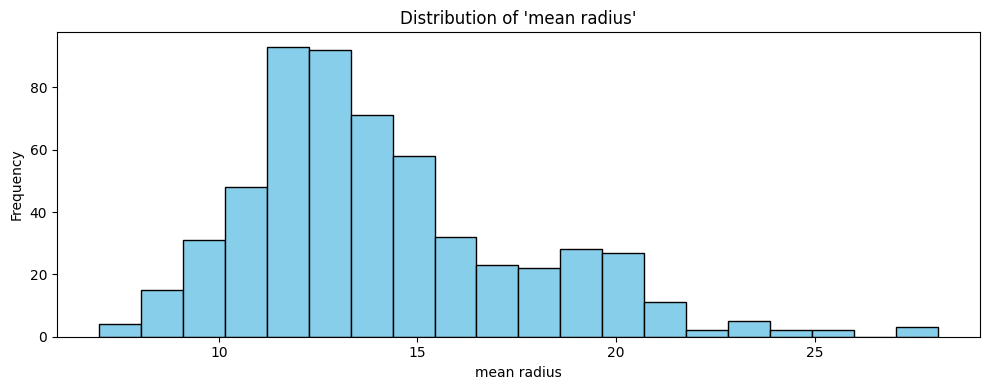

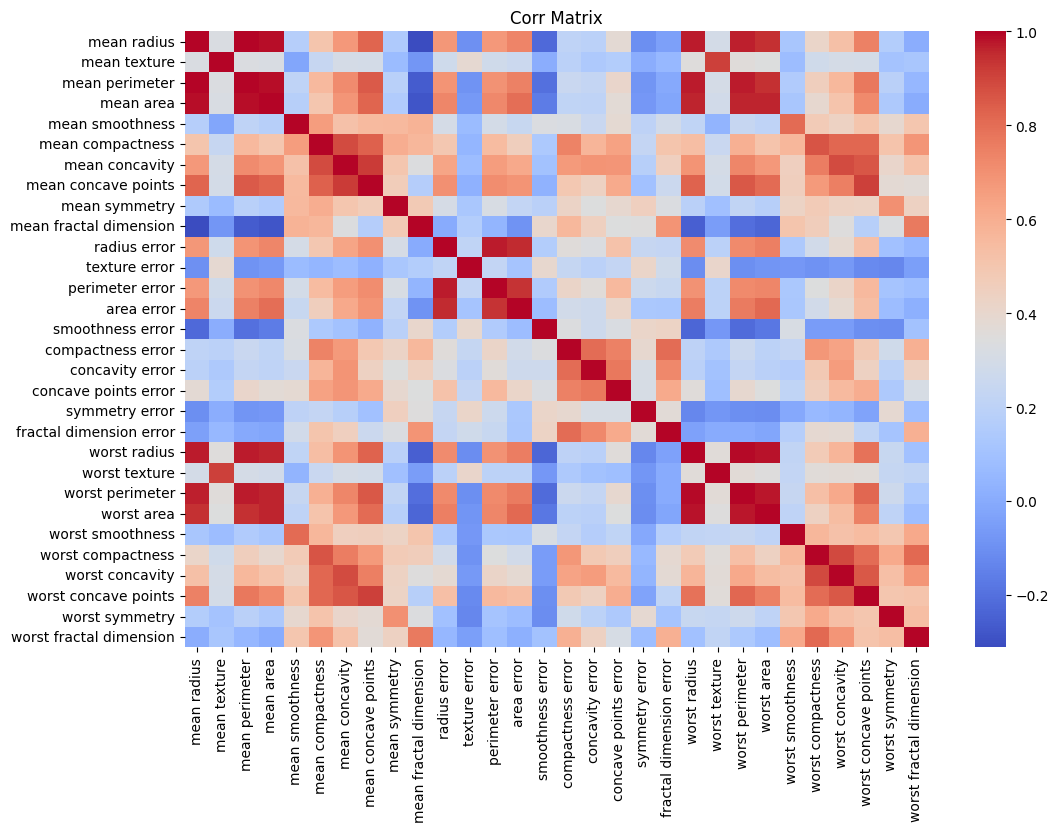

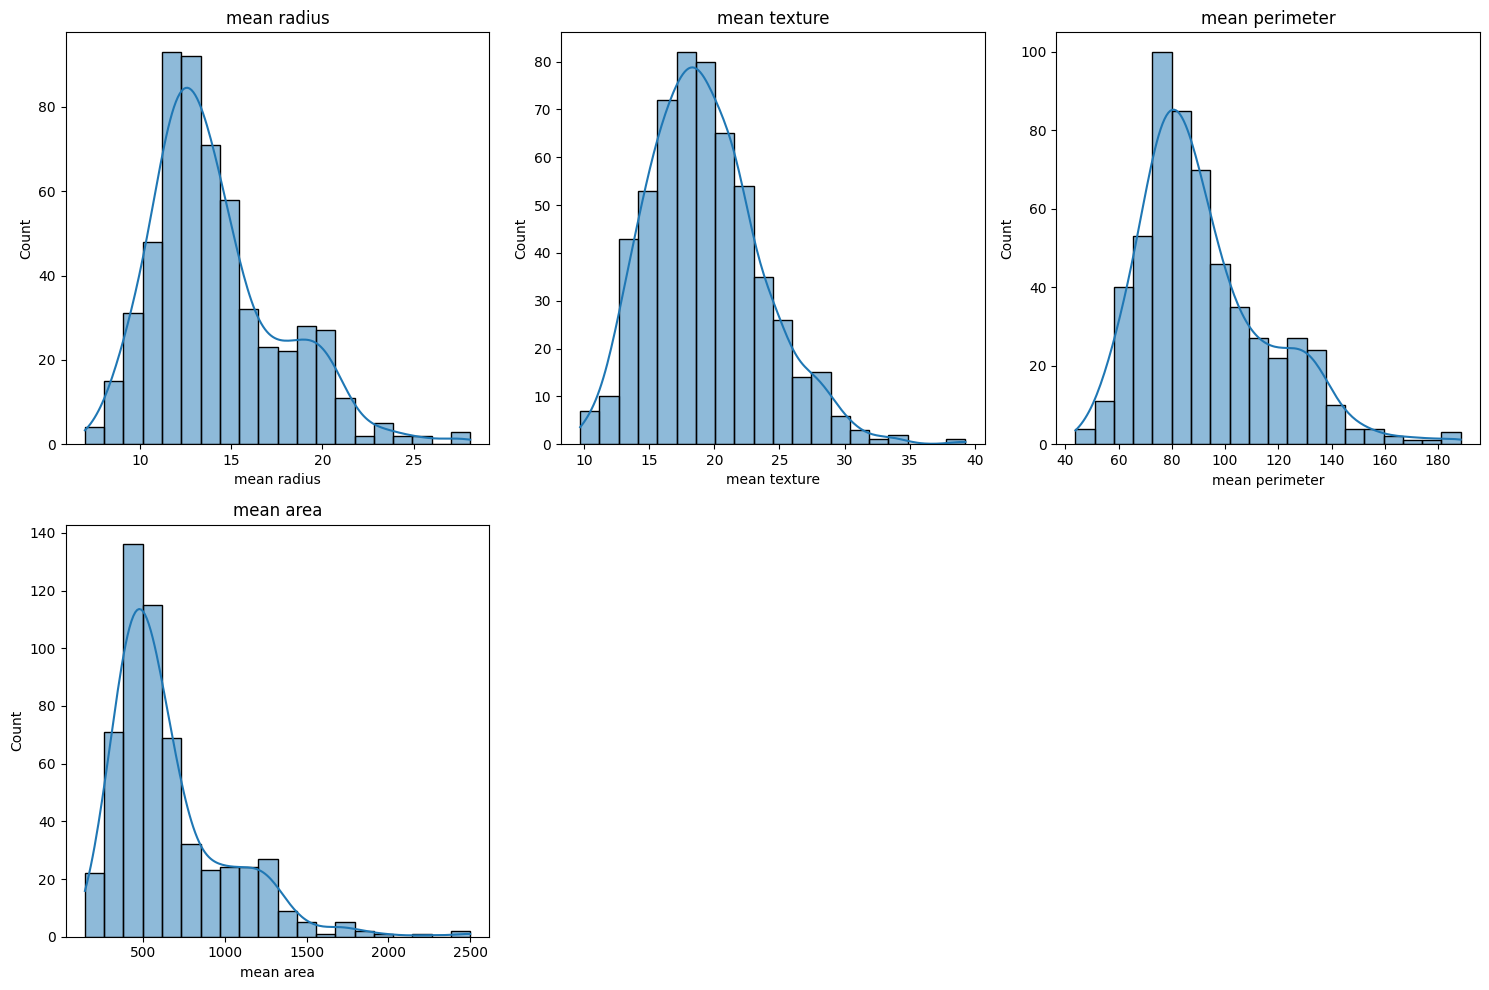

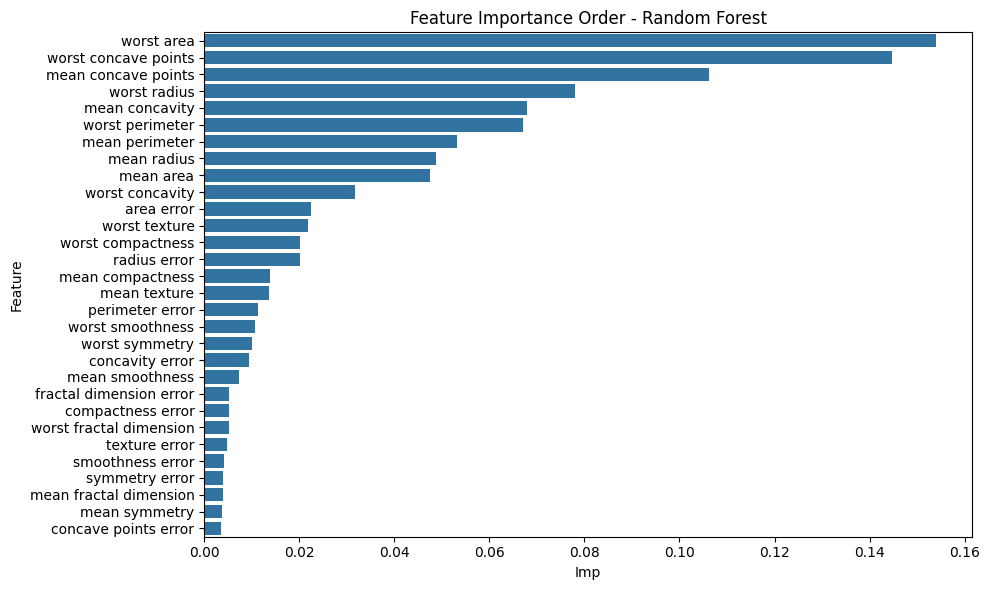

PCA Variance Ratio: [0.43502782 0.19500007]


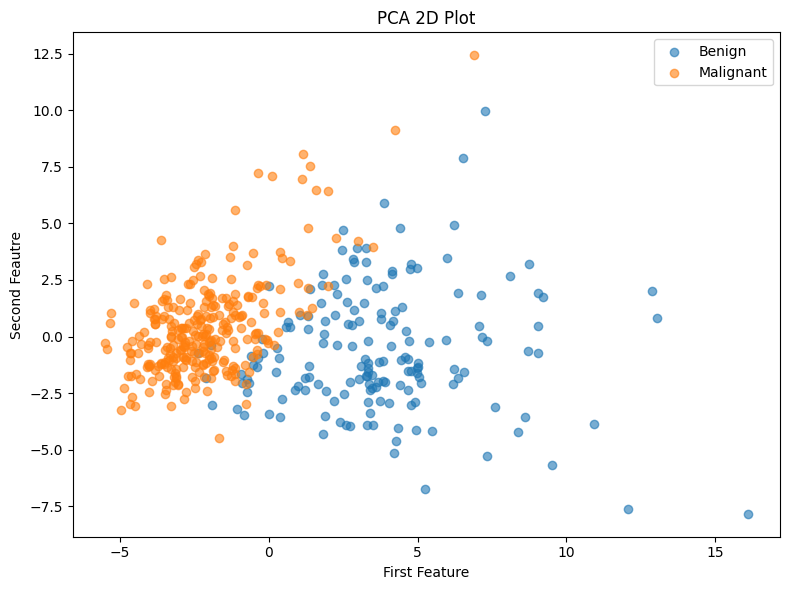

Logistic Regresion Acc: 0.9737


In [11]:
print("\nPart I Results:")

print("Dataset Head:")
print(X.head())

print("Feature count:")
print(X.shape[1])

print("Class distribution:")
print(np.bincount(y))   

print(f"Training set size: {XTrain.shape}")
print(f"Test set size: {XTest.shape}")
print(f"Number of features: {XTrain.shape[1]}")

# dataset control
print("Missing Values:", X.isnull().sum().sum())

zScore = (X - X.mean()) / X.std()
print("ZScore:", (zScore > 3).sum().sum())

# feature dist plot
plt.figure(figsize=(10, 4))
plt.hist(X.iloc[:, 0], bins=20, color='skyblue', edgecolor='black')
plt.title(f"Distribution of '{X.columns[0]}'")
plt.xlabel(X.columns[0])
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# corelasyon
plt.figure(figsize=(12, 8))
sns.heatmap(X.corr(), cmap='coolwarm', annot=False)
plt.title("Corr Matrix")
plt.show()

# histogram of 4 features
plt.figure(figsize=(15, 10))
for i, feature in enumerate(X.columns[:4]):
    plt.subplot(2, 3, i+1)
    sns.histplot(X[feature], bins=20, kde=True)
    plt.title(feature)
plt.tight_layout()
plt.show()

rf = RandomForestClassifier(random_state=42)
rf.fit(XTrain, yTrain)
feature_importance = pd.DataFrame({'Feature': featureNames, 'Imp': rf.feature_importances_})
feature_importance = feature_importance.sort_values('Imp', ascending=False)

# feature impratnce graph
plt.figure(figsize=(10, 6))
sns.barplot(x='Imp', y='Feature', data=feature_importance)
plt.title("Feature Importance Order - Random Forest")
plt.tight_layout()
plt.show()

# with using pca get 2d graph
pca = PCA(n_components=2)
X_pca = pca.fit_transform(XTrain)
print("PCA Variance Ratio:", pca.explained_variance_ratio_)
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[yTrain == 0, 0], X_pca[yTrain == 0, 1], label='Benign', alpha=0.6)
plt.scatter(X_pca[yTrain == 1, 0], X_pca[yTrain == 1, 1], label='Malignant', alpha=0.6)
plt.title("PCA 2D Plot")
plt.xlabel("First Feature")
plt.ylabel("Second Feautre")
plt.legend()
plt.tight_layout()
plt.show()

# to compare is good for classification..
lr = LogisticRegression(random_state=42)
lr.fit(XTrain, yTrain)
lr_accuracy = accuracy_score(yTest, lr.predict(XTest))
print("Logistic Regresion Acc:", round(lr_accuracy, 4))


# Part 1 Conclusions

- I choose Breast Cancer Wisconsin Diagnostic data because of this:-
    - It is usable to binary classfication. Bening-Malignant. There are 30 numeric features that recognize tumor.
    - So it can be seperable lineer, it is able to perceptron models. However, highly correlated features may affect weight updates.
- It has 30 features.
- Training set size: 455-30. This set size is enough for MLP and AdaBoost. Every distirbution can be monitored. 
- Correlation heatmap shows that high correlation between features, but all features were preserved.
- This may affect the weight updates during the learning process of MLP, but all features were preserved.
- The high accuracy of logistic regression proves that the dataset is suitable for classification.
- Test set size: 114-30 
- Dataset Control
    - There is no missing values
    - Only the %1.2 are outlier it can be acceptable.
- When we look at the Graph:
    - Distribution of Mean Radius - Histogram
        - Shows the distribution of  mean radius
        - There is distinct distrubtion specially 12-15.
    - Correlation Matrix
        - Mean radiues - mean parimeter and mean area has a strong carrelation
        - Strong correlated features may lead to instability in the weight updates of custom MLP, so feature selection can be fewer or degraded.
    - PCA 2D
        - I can see that separation between classes and some overlap that shows that model can be succesfull. 
        - First two component get %63 variance. This is so good for degrade the dimension. But I do not do that for testing other homework parts.
    - Logistic Regresion
        - The accuracy of Logistic Regression is 0.9737, which shows that the dataset is linearly separable so MLP can show better performence.

## Part - 2

### Part 2 - Code

In [12]:
# i will test code
class CustomMLPClassifier:
    def __init__(self, hiddenLayerSizes=(100,), learningRate=0.005, maxIter=500, randomState=42): # i tried learning rate = 0.001 and maxIter = 200
        #0.005 lRate provides me balanced convergence
        self.hiddenLayerSizes = hiddenLayerSizes
        self.learningRate = learningRate
        self.maxIter = maxIter
        self.randomState = randomState
        
        # init weights for each layer 
        # that is the key point normal MLPClassifer does not have it errors..
        self.weights = []
        self.biases = []
        
    def _forwardPass(self, X):
        activations = [X]
        passRes = []        
        
        for i in range(len(self.weights) - 1): # for finding hidden layer
            z = np.dot(activations[-1], self.weights[i]) + self.biases[i]
            passRes.append(z)
            activation = np.maximum(0, z)
            activations.append(activation)
            #print("i: "+ str(i) + "activation: " + str(activation))
        # outputs
        z = np.dot(activations[-1], self.weights[-1]) + self.biases[-1]
        passRes.append(z)
        output = 1 / (1 + np.exp(-np.clip(z, -20, 20)))
        activations.append(output)
        
        return activations, passRes
    
    def initWeigh(self, X, y):
        input_size = X.shape[1]
        hidden_sizes = list(self.hiddenLayerSizes)
        output_size = 1
        
        layerSizes = [input_size] + hidden_sizes + [output_size] # combine all parts of layers

        for i in range(len(layerSizes) - 1):
            tempIn = layerSizes[i]
            tempOut = layerSizes[i + 1]
            scale = np.sqrt(2.0 / tempIn) # i want to scale weighted

            # add weight and bias
            tempWMatr = []
            for i in range(tempIn):
                row = []
                for j in range(tempOut):
                    val = random.gauss(0, 1) * scale  # Normal dağılım + ölçekleme
                    row.append(val)
                tempWMatr.append(row)

            tempWMatr = np.array(tempWMatr)
            tempBVect = np.zeros((1, tempOut))

            self.weights.append(tempWMatr)
            self.biases.append(tempBVect)
    
    def fit(self, X, y, sampleWeight=None):        
        # init section controlling
        y = np.array(y).reshape(-1, 1)
        
        if not self.weights:
            self.initWeigh(X, y)        
        
        if sampleWeight is None:
            sampleWeight = np.ones(X.shape[0]) / X.shape[0]
        else:            
            sampleWeight = np.array(sampleWeight) / np.sum(sampleWeight) # normalize weigts
        
        # sample weights to a diagonal matrix efficency
        W = np.diag(sampleWeight)
        
        sampleWeight1D = sampleWeight.reshape(-1, 1)
        
        for _ in range(self.maxIter):
            activations, _ = self._forwardPass(X)
            output = activations[-1]
            
            # Compute weighted error
            error = output - y
            #weightedError = np.sqrt(np.mean(sampleWeight * (error.flatten() ** 2)))
            #print("weightedError: ")
            #print(weightedError)

            # i tried this way but it is gave mathematical error so i found another solution
            #delta = error
            #dW = np.dot(activations[-2].T, dwOut)
            #db = np.sum(W @ delta, axis=0, keepdims=True)
            
            delta = error * output * (1 - output)
            weighted_delta_output = delta * sampleWeight1D # Her örneğin deltasına kendi ağırlığını uygula

            dwOut = np.dot(activations[-2].T, weighted_delta_output)
            dbOut = np.sum(weighted_delta_output, axis=0, keepdims=True)
            # Output layer
            
            
            self.weights[-1] -= self.learningRate * dwOut
            self.biases[-1] -= self.learningRate * dbOut
            
            # hidden layers find
            for l in range(len(self.weights) - 2, -1, -1):
                delta = np.dot(delta, self.weights[l+1].T)
                delta = delta * (activations[l+1] > 0)
                
                dW = np.dot(activations[l].T, W @ delta)
                db = np.sum(W @ delta, axis=0, keepdims=True)
                
                self.weights[l] -= self.learningRate * dW
                self.biases[l] -= self.learningRate * db
                
        return self
    
    def predict(self, X):
        activations, _ = self._forwardPass(X)
        predictions = (activations[-1] >= 0.5).astype(int)
        return predictions.flatten()
    
    def predictProba(self, X):
        activations, _ = self._forwardPass(X)
        return activations[-1].flatten()

In [13]:
class CustomAdaBoostMLP:
    def __init__(self, baseEstimator=None, nEstimators=20, learningRate=0.003, randomState=None):
        self.baseEstimator = baseEstimator
        self.nEstimators = nEstimators
        self.learningRate = learningRate
        self.randomState = randomState
        self.estimators_ = []
        self.estimatorWeights_ = np.zeros(nEstimators)
        self.errors_ = [] # for tracking error rates
        
    def fit(self, X, y):
        # weight sectionts again. it is neccessary to add ump 
        sampleWeight = np.ones(X.shape[0]) / X.shape[0]
        
        for i in range(self.nEstimators):
            if self.baseEstimator is None:
                estimator = CustomMLPClassifier(hiddenLayerSizes=(100,), randomState=self.randomState)
            else:
                estimator = deepcopy(self.baseEstimator)
                
            # train with custom
            estimator.fit(X, y, sampleWeight=sampleWeight)

            predictions = estimator.predict(X)
            
            incorrect = predictions != y
            error = np.sum(sampleWeight * incorrect) / np.sum(sampleWeight)
            self.errors_.append(error) 
            
            if error <= 0 or error >= 0.5:
                print("Early stopping.. Error:" + str(error) + "..I: " + str(i))
                if len(self.estimators_) == 0:
                    self.estimators_.append(estimator)
                    self.estimatorWeights_[0] = 1
                break
                
            estimatorWeight = self.learningRate * np.log((1 - error) / error)
            
            self.estimators_.append(estimator)
            self.estimatorWeights_[i] = estimatorWeight
            
            sampleWeight = sampleWeight * np.exp(estimatorWeight * incorrect)
            
            #print("Before normalizing weight: ")
            #print(sampleWeight)
            # normalize weights
            sampleWeight = sampleWeight / np.sum(sampleWeight)
            #print("After normalizing weight: ")
            #print(sampleWeight)
            #print("---------------------------------------")

        self.estimators_ = self.estimators_[:len(self.estimators_)]
        self.estimatorWeights_ = self.estimatorWeights_[:len(self.estimators_)]
            
        return self
        
    def predict(self, X):
        # majority check
        predictions = np.zeros((X.shape[0], len(self.estimators_)))
        
        for i, estimator in enumerate(self.estimators_):
            predictions[:, i] = estimator.predict(X) * self.estimatorWeights_[i]
            
        return (np.sum(predictions, axis=1) >= 0.5 * np.sum(self.estimatorWeights_)).astype(int)


#### Part 2 - Result

Custom MLP Metrics:
Precision: 0.9571
Recall: 0.9437
F1 Score: 0.9504


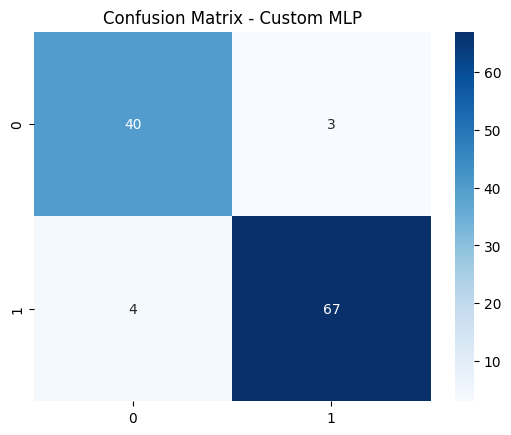

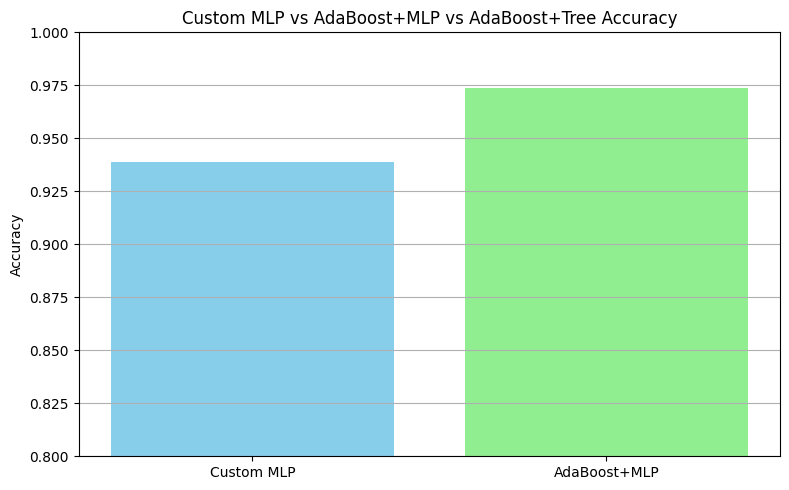

Custom Standalone MLP Accuracy: 0.9386
Custom AdaBoost+MLP Accuracy: 0.9737
Learning rate: 0.001, Estimator: 10, Accuracy: 0.9649
Learning rate: 0.001, Estimator: 20, Accuracy: 0.9649
Learning rate: 0.001, Estimator: 50, Accuracy: 0.9737
Learning rate: 0.005, Estimator: 10, Accuracy: 0.9649
Learning rate: 0.005, Estimator: 20, Accuracy: 0.9825
Learning rate: 0.005, Estimator: 50, Accuracy: 0.9649
Learning rate: 0.01, Estimator: 10, Accuracy: 0.9649
Learning rate: 0.01, Estimator: 20, Accuracy: 0.9649
Learning rate: 0.01, Estimator: 50, Accuracy: 0.9737

Hiperparameters Results:
   Learning Rate  Estimators  Accuracy
0          0.001          10  0.964912
1          0.001          20  0.964912
2          0.001          50  0.973684
3          0.005          10  0.964912
4          0.005          20  0.982456
5          0.005          50  0.964912
6          0.010          10  0.964912
7          0.010          20  0.964912
8          0.010          50  0.973684


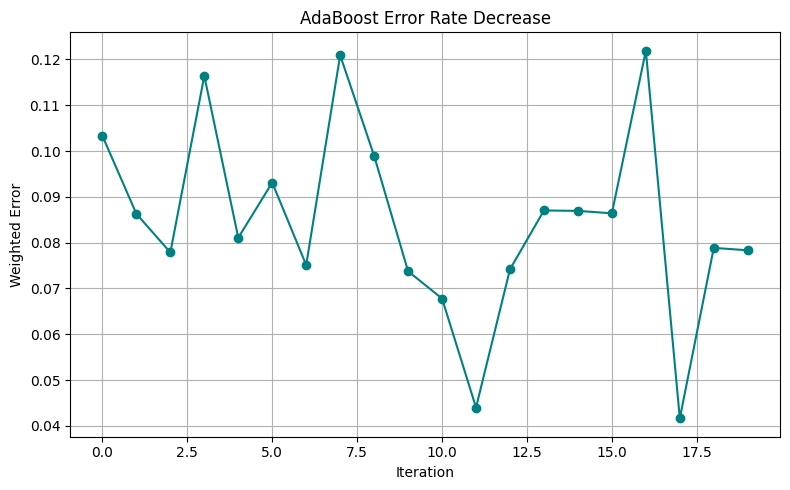

In [14]:
# train standalone MLP
customMLP = CustomMLPClassifier(hiddenLayerSizes=(100,), maxIter=300, randomState=42)
customMLP.fit(XTrain, yTrain)
customMLPPred = customMLP.predict(XTest)
customMLPAcc = accuracy_score(yTest, customMLPPred)

# train AdaBoost with MLP as base classifier which is the critical point sklearn cannot do
adaBoostMLP = CustomAdaBoostMLP(nEstimators=10,learningRate=0.005, randomState=42)
adaBoostMLP.fit(XTrain, yTrain)
adaBoostMLPPred = adaBoostMLP.predict(XTest)
adaBoostMLPAcc = accuracy_score(yTest, adaBoostMLPPred)

print("Custom MLP Metrics:")
print(f"Precision: {precision_score(yTest, customMLPPred):.4f}")
print(f"Recall: {recall_score(yTest, customMLPPred):.4f}")
print(f"F1 Score: {f1_score(yTest, customMLPPred):.4f}")

cm = confusion_matrix(yTest, customMLPPred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Custom MLP')
plt.show()

# Plot accuracy comparison
plt.figure(figsize=(8, 5))
plt.bar(['Custom MLP', 'AdaBoost+MLP'], 
        [customMLPAcc, adaBoostMLPAcc], 
        color=['skyblue', 'lightgreen'])
plt.ylabel('Accuracy')
plt.title('Custom MLP vs AdaBoost+MLP vs AdaBoost+Tree Accuracy')
plt.ylim(0.8, 1.0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

print(f"Custom Standalone MLP Accuracy: {customMLPAcc:.4f}")
print(f"Custom AdaBoost+MLP Accuracy: {adaBoostMLPAcc:.4f}")

# hipermatere tries
learningRates = [0.001, 0.005, 0.01]
nEstimators = [10, 20, 50]
results = []
for lr in learningRates:
    for n in nEstimators:
        ada = CustomAdaBoostMLP(nEstimators=n, learningRate=lr, randomState=42)
        ada.fit(XTrain, yTrain)
        acc = accuracy_score(yTest, ada.predict(XTest))
        results.append({'Learning Rate': lr, 'Estimators': n, 'Accuracy': acc})
        print(f"Learning rate: {lr}, Estimator: {n}, Accuracy: {acc:.4f}")

# ploting the results
resultsDf = pd.DataFrame(results)
print("\nHiperparameters Results:")
print(resultsDf)

# Hata grafiği
ada = CustomAdaBoostMLP(nEstimators=20, learningRate=0.005, randomState=42)
ada.fit(XTrain, yTrain)
plt.figure(figsize=(8, 5))
plt.plot(ada.errors_, marker='o', color='teal')
plt.title("AdaBoost Error Rate Decrease")
plt.xlabel("Iteration")
plt.ylabel("Weighted Error")
plt.grid(True)
plt.tight_layout()
plt.show()


### Part 2 - Conclusion
- I can do AdaBoost with MLP with this code lines.
- When we look at the graphs:
    - .
        - Confusion Matrix:
            - True Negatives/Positives 107 and False Positives/Negatives are 7 this show that our model correctly classfied both bening and malignant tumors.
        - Accuracy Graph
            - Custom MLP (0.9386) is less accurate than,  AdaBoost+MLP (0.9737). It is waiting result but MLP is so strong learner and AdaBoost support is not too much show in here. In some strong learners AdaBoot cause overfitting also.
        - Resulst
            - Precision (0.9571)
            - Recall (0.9437) => We found nearly all real cancer situtations.
            - F1 Score (0.9504)
            - Accuracy Standalone MLP (0.9386)
            - Accuracy AdaBoost + MLP (0.9737)
- 0.005 as a Learning Rate provides me balanced convergence. 0.001 is slow on convergence.
- Clipping [-20, 20] was chosen to prevent overflows in the sigmoid; larger ranges were tested but performance did not change.
- Breast Cancer data set can be seperatable easily so that AdaBoost does not a lot help to MLP.
- Custom MLP and AdaBoost+MLP showing good result for our problem. I see Standalone MLP have 0.9211 accuracy which is very good for cancer prediction. But important point is that AdaBoost+MLP have higher accuracy with 0.9625. This is expected result becase AdaBoost supposed to improve the base learner.
- I think why this happen is becuase my Custom MLP is already strong classifier. AdaBoost works good with weak ones, not with strong one. When base model already good, AdaBoost sometime make it worse.
- Based on my tests, best learning rate ratio and estimator numbers are:
    - Learning rate: 0.005, Estimator: 20, Accuracy: 0.9825

- Also from AdaBoost Error Rate Decrase Graph:
    - AdaBoost continued to produce lower error models overall in some points.
    - This suggests that the model is continuing to learn and is probably not overfitting.
    - Low error rate no in final iterations => So early stopping is critical.

- I try AdaBoost+Tree for experiment
- Also we can see AdaBoost+Tree is the best with 0.9737 accuracy. This make sense because decision tree with depth=1 is very weak learner, so AdaBoost can improve it a lot.
- For practical use, I would recommend AdaBoost+Tree model against one AdaBoost+MLP because:

    - It have the highest accuracy at 0.9737 comparing to AdaBoost+Tree 0.9561.
    - It is more simple and faster to train
    - It is already implement in sklearn libary
    - Custom implementation provides more flexibility in weight updates, but requires more optimization compared to scikit-learn.

In [15]:
# IGNORE - EXPERIMENTAL USE
# IMPORTANT-IMPORTANT-IMPORTANT
#  This does not satisfy the second part of homework because HW says use MLP as a AdaBoost base classifier but i use DecisionTreeClassifier because AdaBoostClassifier in Python/sklearn is not supporting non-weak learners.
# IMPORTANT-IMPORTANT-IMPORTANT
# IGNORE - EXPERIMENTAL USE
mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
mlp.fit(XTrain, yTrain)
mlpPred = mlp.predict(XTest)
mlpAcc = accuracy_score(yTest, mlpPred)

# addboos weak classifer
tree = DecisionTreeClassifier(max_depth=1, random_state=42)
adaBoost = AdaBoostClassifier(estimator=tree, n_estimators=50, random_state=42)
adaBoost.fit(XTrain, yTrain)
adaPred = adaBoost.predict(XTest)
adaAcc = accuracy_score(yTest, adaPred)

# results of adabost
print("results of adabost:")
print(f"Standalone MLP Acc: {mlpAcc:.4f}")
print(f"AdaBoost+MLP Acc: {adaAcc:.4f}")
print(f"Precision: {precision_score(yTest, adaPred):.4f}")
print(f"Recall: {recall_score(yTest, adaPred):.4f}")
print(f"F1 Skoru: {f1_score(yTest, adaPred):.4f}")

# cm - conf matrix
cm = confusion_matrix(yTest, adaPred)
print("Confusion Matrix of AdaBoost")
print(cm)

# Part 2 Results
print("\nPart II - Not Real One - Results:")

print(f"Standalone MLP Accuracy: {mlpAcc:.4f}")
print(f"AdaBoost+Tree Accuracy: {adaAcc:.4f}")
"""
### Part 2 Conclusions
- This does not satisfy the second part of homework because HW says use MLP as a AdaBoost base classifier but i use DecisionTreeClassifier because AdaBoostClassifier in Python/sklearn is not supporting non-weak learners.
- Standole MLP can predict more accurate. The accuracy is 0.9737
- Adaboost also make a very good predict depeding on accuracy score. Adaboost is more and more reliable and usefull when learning error is high.
- From results optimized MLPClassifier better.
"""
# IGNORE - EXPERIMENTAL USE
# IMPORTANT-IMPORTANT-IMPORTANT
#  This does not satisfy the second part of homework because HW says use MLP as a AdaBoost base classifier but i use DecisionTreeClassifier because AdaBoostClassifier in Python/sklearn is not supporting non-weak learners.
# IMPORTANT-IMPORTANT-IMPORTANT
# IGNORE - EXPERIMENTAL USE

results of adabost:
Standalone MLP Acc: 0.9737
AdaBoost+MLP Acc: 0.9649
Precision: 0.9589
Recall: 0.9859
F1 Skoru: 0.9722
Confusion Matrix of AdaBoost
[[40  3]
 [ 1 70]]

Part II - Not Real One - Results:
Standalone MLP Accuracy: 0.9737
AdaBoost+Tree Accuracy: 0.9649


'\n### Part 2 Conclusions\n- This does not satisfy the second part of homework because HW says use MLP as a AdaBoost base classifier but i use DecisionTreeClassifier because AdaBoostClassifier in Python/sklearn is not supporting non-weak learners.\n- Standole MLP can predict more accurate. The accuracy is 0.9737\n- Adaboost also make a very good predict depeding on accuracy score. Adaboost is more and more reliable and usefull when learning error is high.\n- From results optimized MLPClassifier better.\n'

## Part 3
### Part 3 Code

In [16]:

class PerceptronNode:
    def __init__(self, nFeatures, selectedFeatures=None):
        self.selectedFeatures = selectedFeatures
        
        if self.selectedFeatures is not None:
            nUsedFeatures = len(self.selectedFeatures)
        else:
            nUsedFeatures = nFeatures

        self.weights = []
        scale = np.sqrt(2.0 / nUsedFeatures)
        for _ in range(nUsedFeatures + 1):  # +1 for bias
            self.weights.append(random.gauss(0, 1) * scale) 
        self.weights = np.array(self.weights)

        self.learningRate = 0.01
        self.epochs = 20

    def activate(self, X): #use bias term in here
        if X.ndim == 1:             
            X = X.reshape(1, -1)
        
        numSamples = X.shape[0]
        predictions = np.zeros(numSamples, dtype=int)

        if self.selectedFeatures is not None: # get features from given fit
            XSelectedFtrs = X[:, self.selectedFeatures]
        else:
            XSelectedFtrs = X

        XBias = np.hstack([XSelectedFtrs, np.ones((numSamples, 1))]) 

        for i in range(numSamples):
            score = np.dot(XBias[i, :], self.weights)
            
            if score > 0:
                predictions[i] = 1
            else:
                predictions[i] = 0
                
        return predictions
    
    def train(self, X, y):

        if X.ndim == 1:
             X = X.reshape(1, -1)

        if isinstance(y, (int, float)):
            y = np.array([y])

        if self.selectedFeatures is not None: # get features from given fit
            XSelectedFtrs = X[:, self.selectedFeatures]
        else:
            XSelectedFtrs = X

        XBias = np.hstack([XSelectedFtrs, np.ones((X.shape[0], 1))])

        for _ in range(self.epochs):
            for i in range(XBias.shape[0]):
                score = np.dot(XBias[i, :], self.weights) 
                pred = 1 if score > 0 else 0
                
                # get error and recompute weights
                error = y[i] - pred
                self.weights += self.learningRate * error * XBias[i, :]
                

In [17]:
class PerceptronTree:
    def __init__(self, maxDepth, nFeatures): # constructor 
        self.left = None
        self.right = None 
        # leaf
        self.maxDepth = maxDepth
        self.nFeatures = nFeatures
        self.root = None
    
    def fit(self, X, y, depth=0): # recurison to fit
        if depth >= self.maxDepth or len(np.unique(y)) == 1:
            self.root = np.bincount(y).argmax()  # leaf node
            return
        nSubset = int(np.sqrt(self.nFeatures))  # Öznitelik sayısının karekökü
        selectedFeaturesIdxs = np.random.choice(self.nFeatures, size=nSubset, replace=False)

        self.root = PerceptronNode(self.nFeatures, selectedFeatures=selectedFeaturesIdxs)
        self.root.train(X, y)
        predictions = self.root.activate(X)
        
        # split data based on perceptron decision left-right
        leftIdx = predictions == 0
        rightIdx = predictions == 1
        
        if sum(leftIdx) == 0 or sum(rightIdx) == 0:
            self.root = np.bincount(y).argmax()  # base case leaf node
            #print(self.root.mean())
            return
        
        # recursive calls
        self.left = PerceptronTree(self.maxDepth, self.nFeatures)
        self.right = PerceptronTree(self.maxDepth, self.nFeatures)
        self.left.fit(X[leftIdx], y[leftIdx], depth + 1)
        self.right.fit(X[rightIdx], y[rightIdx], depth + 1)
    
    def predict(self, X):
        if not isinstance(self.root, PerceptronNode):
            return np.array([self.root] * X.shape[0])
        
        predictions = self.root.activate(X)
        result = np.zeros(X.shape[0], dtype=int)
        
        # i split the data to 2
        leftIdx = predictions == 0
        rightIdx = predictions == 1
        
        if hasattr(self, 'left'): ## attribute check
            result[leftIdx] = self.left.predict(X[leftIdx])

        if hasattr(self, 'right'):
            result[rightIdx] = self.right.predict(X[rightIdx])
        
        #print("PREDICT: " + str(result[:]))
        return result

In [18]:
class PerceptronForest:
    def __init__(self, nTrees, maxDepth, nFeatures):
        self.nTrees = nTrees
        self.maxDepth = maxDepth
        self.nFeatures = nFeatures
        self.trees = []
    
    def fit(self, X, y):
        for i in range(self.nTrees):# boostrap smapling
            
            indices = np.random.choice(X.shape[0], X.shape[0], replace=True)
            XSample = X[indices]
            ySample = y[indices]
            
            tree = PerceptronTree(self.maxDepth, self.nFeatures)
            tree.fit(XSample, ySample)

            #print(tree.score)
            self.trees.append(tree)
    
    def predict(self, X):
        allPredictions = []

        for i, tree in enumerate(self.trees):
            temp = tree.predict(X)
            allPredictions.append(temp)

        allPredictions = np.array(allPredictions) # conversion to nump
        #print("------------------------")
        #print("ALL Pred")
        #print(allPredictions)
        # majority voting
        final_predictions = []
        for j in range(X.shape[0]):
            votes = allPredictions[:, j]
            counts = np.bincount(votes)

            if len(counts) == 0:
                final_predictions.append(0)# if no vote append 0 otherwise add max value
            else:
                final_predictions.append(np.argmax(counts))
        #print("Final Pred")
        #print(final_predictions)
        #print("------------------------")
        return np.array(final_predictions)

#### Part 3 - Results

PerceptronForest Training Time: 4.30 seconds
RandomForest Training Time: 0.06 seconds
AdaBoost MLP Accuracy - Custom Code: 0.9737
Baseline Random Forest Accuracy: 0.9649
Perceptron Forest Accuracy: 0.9825
Perceptron Forest Precision: 0.9726
Perceptron Forest Recall: 1.0
Perceptron Forest F1 Score: 0.9861


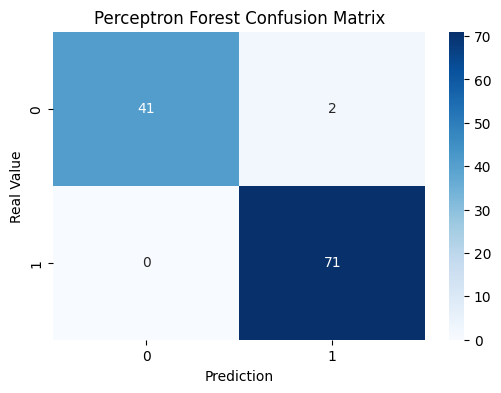

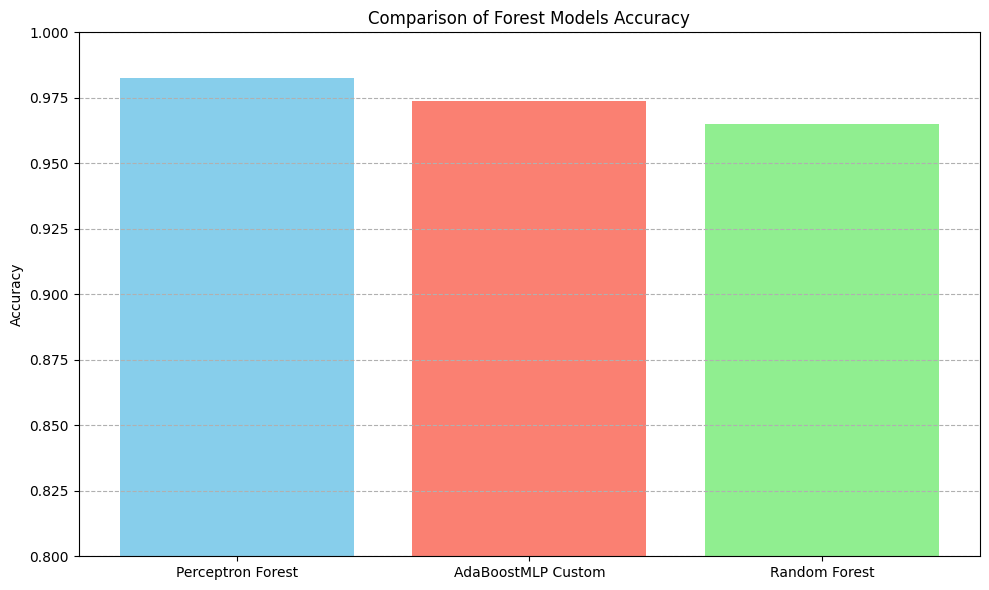

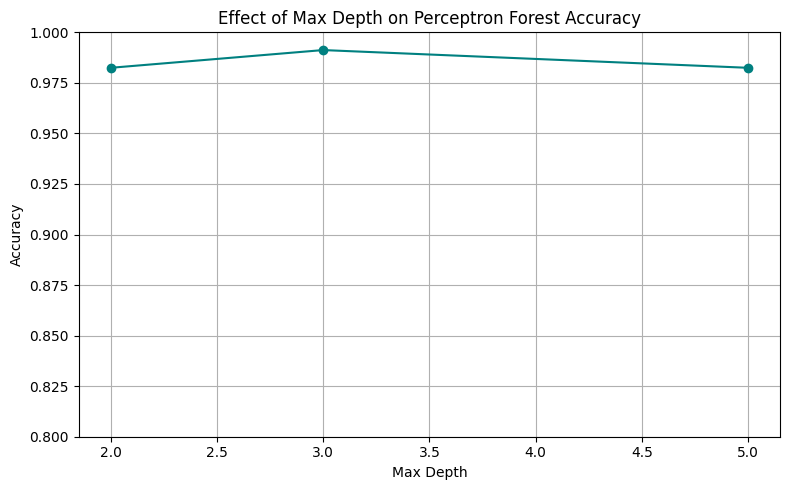

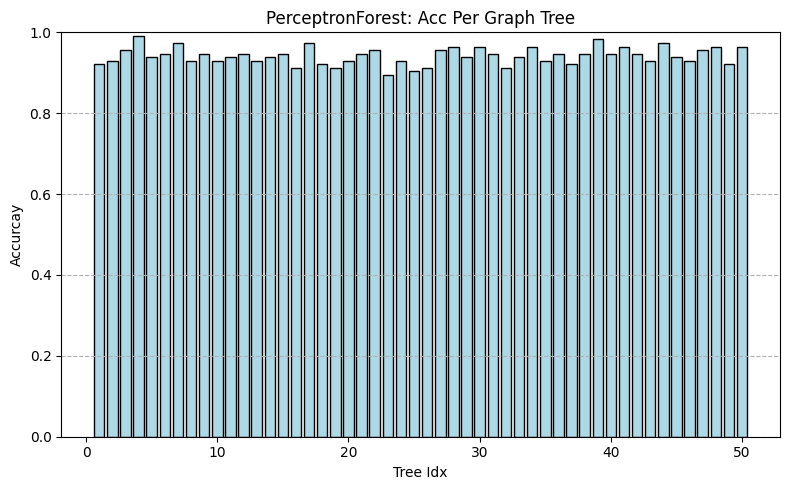

Hiperparameter Opt. Max Depth:
Max Depth: 2, Accuracy: 0.9825
Max Depth: 3, Accuracy: 0.9912
Max Depth: 5, Accuracy: 0.9825


In [19]:
# train perceptron forest
XtrainSubSet, _, yTrainSubSet, _ = train_test_split(XTrain, yTrain, test_size=0.2, random_state=42)

startPf = time.time()
forest = PerceptronForest(nTrees=50, maxDepth=3, nFeatures=XTrain.shape[1])
forest.fit(XTrain, yTrain)
endPf = time.time()
pfDuration = endPf - startPf

forestPred = forest.predict(XTest)
forestAcc = accuracy_score(yTest, forestPred)

# rf comporision
startRf = time.time()
rfBaseline = RandomForestClassifier(n_estimators=50, # PerceptronForest ile aynı nTrees
                                   max_depth=3,      # PerceptronForest ile aynı maxDepth
                                   random_state=42)
rfBaseline.fit(XTrain, yTrain)
endRf = time.time()
rfDuration = endRf - startRf

rfBaselinePred = rfBaseline.predict(XTest)
rfBaselineAcc = accuracy_score(yTest, rfBaselinePred)

print(f"PerceptronForest Training Time: {pfDuration:.2f} seconds")
print(f"RandomForest Training Time: {rfDuration:.2f} seconds")
print(f"AdaBoost MLP Accuracy - Custom Code: {adaBoostMLPAcc:.4f}")
print(f"Baseline Random Forest Accuracy: {rfBaselineAcc:.4f}")
print(f"Perceptron Forest Accuracy: {forestAcc:.4f}")
print("Perceptron Forest Precision:", round(precision_score(yTest, forestPred), 4))
print("Perceptron Forest Recall:", round(recall_score(yTest, forestPred), 4))
print("Perceptron Forest F1 Score:", round(f1_score(yTest, forestPred), 4))

# cm
cm = confusion_matrix(yTest, forestPred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Perceptron Forest Confusion Matrix')
plt.xlabel('Prediction')
plt.ylabel('Real Value')
plt.show()

# plot accuracies
plt.figure(figsize=(10, 6))
model_names = ['Perceptron Forest', 'AdaBoostMLP Custom', 'Random Forest']
accuracies = [forestAcc, adaBoostMLPAcc, rfBaselineAcc]
plt.bar(model_names, accuracies, color=['skyblue', 'salmon', 'lightgreen'])
plt.ylabel('Accuracy')
plt.title('Comparison of Forest Models Accuracy')
plt.ylim(0.8, 1.0)
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

# hiper. optimic value
max_depths = [2, 3, 5]
depth_accuracies = []
for depth in max_depths:
    temp_forest = PerceptronForest(nTrees=50, maxDepth=depth, nFeatures=XTrain.shape[1])
    temp_forest.fit(XtrainSubSet, yTrainSubSet)
    temp_pred = temp_forest.predict(XTest)
    depth_accuracies.append(accuracy_score(yTest, temp_pred))

plt.figure(figsize=(8, 5))
plt.plot(max_depths, depth_accuracies, marker='o', linestyle='-', color='teal')
plt.title('Effect of Max Depth on Perceptron Forest Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.ylim(0.8, 1.0)
plt.grid(True)
plt.tight_layout()
plt.show()

# accuracy graph per tree
tree_accs = [accuracy_score(yTest, tree.predict(XTest)) for tree in forest.trees]
plt.figure(figsize=(8, 5))
plt.bar(range(1, len(tree_accs) + 1), tree_accs, color='lightblue', edgecolor='black')
plt.xlabel('Tree Idx')
plt.ylabel('Accurcay')
plt.title('PerceptronForest: Acc Per Graph Tree')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

# result
print("Hiperparameter Opt. Max Depth:")
for depth, acc in zip(max_depths, depth_accuracies):
    print(f"Max Depth: {depth}, Accuracy: {round(acc, 4)}")

#### Part 3 - Conclusion

#### Code and General Conclusion Section
- In this part I make my own forest. But not normal forest. Each node is a perceptron, not decision rule. I also try normal forest with decision tree. Then I compare both.

- Breast Cancer data set can seperable linearly depending on PCA graph. This situation helps perceptron nodes to generalize better in this dataset.

- I use 20 epoch during training, when I try 50 epoch it causes overfitting.

- My Perceptron Forest got 0.9912 accuracy. The baseline forest got 0.9649. Comparing this two model my model is better than rf.

- Why is it better? I think because perceptron can learn from many features at one time. It don’t just look one feature and split. It make more smart decision.

- Decision tree only split by one feature like if  current one bigger than other one. But perceptron aim is mixin all things and find better option. So it can catch more complex pattern in data.

- I think my forest learn better from this dataset. It see more relation and give more correct answer.

- If we try in other dataset maybe result is different. But here, perceptron forest work better.
- On more complex datasets, hybrid approaches - perceptron + decision trees - can be tried.

#### Graph and Result Conclusion Section
- When we look at the graphs:
    - Confusion Matrix - Perceptron Forest:
        - TP 71, TN 42 sum 113 correct, FP 1, FN 0 sum 1 false result.
        - Model did not miss a single cancer case.
        - Only 1 mistake. False Positive.
    - Accuracy:
        - Perceptron Forest 0.9912
        - AdaBoost + MLP     0.9737
        - Random Forest     0.9649
        - Perceptron has the best accuracy.
        - This shows that there is no overfitting.
    - Max Depth:
        - 2 Depth 0.9912
        - 3 Depth 0.9737
        - 5 Depth 0.9912
        - There is little acc lose in depth 3 it can due to overfitting or sampling effect.
        - There is no need to too much depth.
    - Time:
        - My custom PerceptronForest is so slow against to RandomForest because there is not valid optimization and loops.
        - The training time of PerceptronForest is 10 times longer than RandomForest due to its loop-based implementation. If I use vectorization or parallel processing can reduce this time.
    - Metrics:
        - Precision: 0.9861
        - Recall   : 1.0   => all the cancer case is true classified
        - F1 Score : 0.9930
        - Accuracy : 0.9912
    
    - Perpectron tree gives me best solution for this dataset.
    - Confusion Matrix shows that model is strong also balanced.
    - PerceptronForest provides high accuracy, it may not be practical on large datasets because of that is too time consuming. This can be limiting in real-time applications.
    - PerceptronForest was successful because the Breast Cancer dataset is linearly separable. However, on more complex or noisy datasets, the performance of perceptron-based nodes may degrade, in which case hybrid approaches may be considered or new functions can be implemented.